# 09 · Framework evaluation: how does graph quality affect actionable RCA?

**Objective.** The main experiment of the thesis. One integrated framework runs on many graphs:

graph → SCM → root cause analysis → interventions → counterfactual explanations

We measure how errors in the graph propagate to each downstream task.

**Graphs compared**

| | Graph | Role |
|---|---|---|
| G1 | expert graph | reference |
| G2 | discovered graph (PCMCI+, leave-one-scenario-out, made acyclic) | data-driven |
| G3 | perturbed expert graphs: edge **deletion**, false-edge **insertion**, edge **reversal** at 10%, 25% and 50% of the expert edges, 5 random seeds each | controlled graph errors |
| — | empty graph (no edges) | lower bound: the same SCM family without structure |

Perturbed graphs stay acyclic, because the SCM needs it. For every graph the whole pipeline is rerun: mechanisms are refitted per held-out scenario, RCA, the replay of the real manipulations, and the counterfactual search.

**Downstream measures** (all leave one scenario out, 25 held-out runs)
- **RCA:** MAP@3, Top-1, median separation margin (notebook 06).
- **Interventions:** mean predicted probability that the alarms which really fired after the real manipulations fire in the replay (notebook 07), over all observed alarms and over supported alarms only.
- **Counterfactuals:**
  - share of runs with a valid explanation and mean validity probability (judged on alarms with a fitted mechanism only, see notebook 08),
  - mean target improvement,
  - recall of true causes among the recommended actions,
  - whether the recommendation equals the one obtained with the expert graph (**recommendation stability**).

**Statistics.** Relationships between graph quality and downstream quality are measured with Spearman rank correlation over the perturbed graphs. 95% intervals come from bootstrap resampling of the graphs. Runs of one graph are compared with the expert graph by paired Wilcoxon tests. We do **not** assume that a better graph F1 means better downstream results; the analysis tests it.

In [1]:
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats

from causal_rca import causal_discovery as cd
from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import graph_evaluation as ge
from causal_rca import preprocessing as pp

ev.set_plot_style()
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
SUBSYSTEM = 'coolant'
INTERVAL = 0.5
KINDS = ['delete', 'insert', 'reverse']
FRACTIONS = [0.1, 0.25, 0.5]
SEEDS = range(5)
N_SAMPLES = 100
SEED = 0

In [2]:
# data, ground truth, observed manipulation onsets and the graphs to compare
view_data, _ = pp.load_view_data(data.PROCESSED_DIR, f'{SUBSYSTEM}_dt{INTERVAL:g}')
tables = data.RESULTS_DIR / 'tables'
splits = pd.read_csv(tables / f'02_{SUBSYSTEM}_splits.csv')
runs = data.load_fault_runs()
experiments = data.load_experiments()
manipulated = data.manipulated_by_recording(runs, experiments)
expert = ge.simple_digraph(data.load_expert_graph(subsystem=SUBSYSTEM))
NODES = sorted(expert.nodes)
types = {n: ('Alarm' if expert.nodes[n]['kind'] == 'Alarm' else 'Binary') for n in NODES}
ALARMS = sorted(n for n in NODES if types[n] == 'Alarm')

events = pp.mark_changes(pp.parse_values(pp.load_all_events(
    [r for r in pp.discover_recordings(data.RAW_DIR) if r.subsystem == SUBSYSTEM], data.RAW_DIR)))
changes = data.fault_variable_changes(events, runs[runs.subsystem == SUBSYSTEM], experiments)
onset_steps = {(r, v): int(np.ceil(round(t / INTERVAL, 9))) for r, v, t in
               zip(changes.recording_id, changes.variable, changes.first_change_after_start_s) if not np.isnan(t)}

edges = pd.read_csv(tables / f'03_{SUBSYSTEM}_edges.csv')
discovered_dag = {gid: ge.to_dag(cd.edges_to_graph(g, NODES))[0] for gid, g in edges.groupby('graph_id')}
empty = nx.DiGraph()
empty.add_nodes_from(NODES)

variants = {'expert': {'kind': 'expert', 'fraction': 0.0, 'seed': -1, 'getter': lambda fold: expert, 'graph': expert},
            'discovered': {'kind': 'discovered', 'fraction': np.nan, 'seed': -1,
                           'getter': lambda fold: discovered_dag[f'discovered_without_{fold}'], 'graph': discovered_dag['discovered']},
            'empty': {'kind': 'empty', 'fraction': 1.0, 'seed': -1, 'getter': lambda fold: empty, 'graph': empty}}
for kind in KINDS:
    for fraction in FRACTIONS:
        for seed in SEEDS:
            g = ge.perturb_graph(expert, kind, fraction, seed)
            variants[f'{kind} {fraction:g} s{seed}'] = {'kind': kind, 'fraction': fraction, 'seed': seed,
                                                        'getter': (lambda graph: (lambda fold: graph))(g), 'graph': g}
print(len(variants), 'graphs')

48 graphs


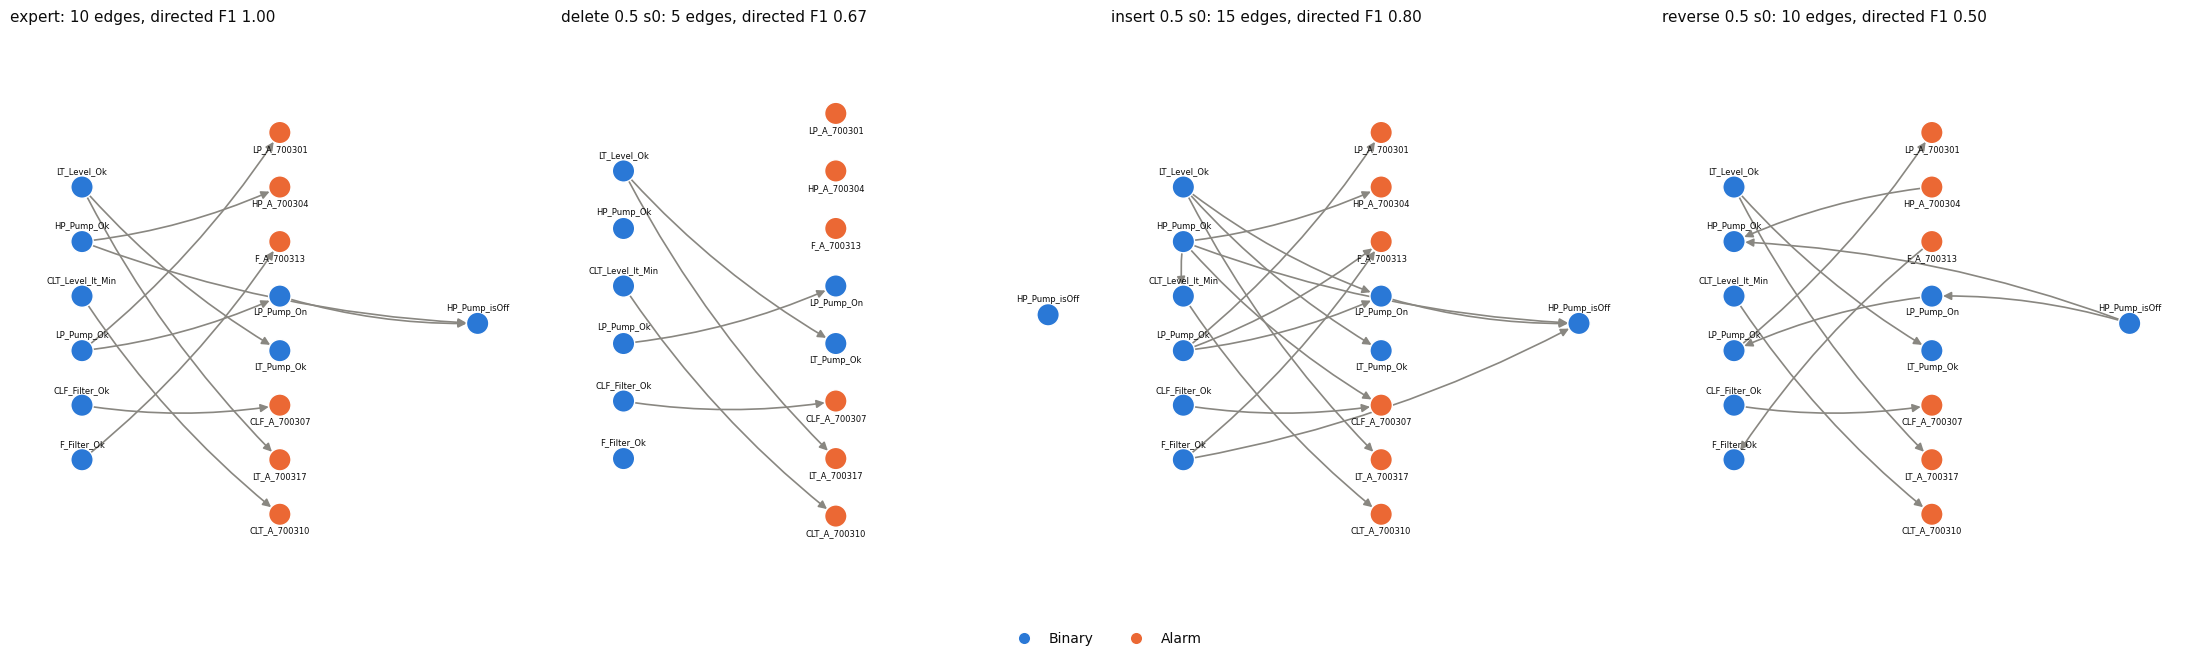

In [3]:
# figure 1: one perturbed graph of every kind (50%, seed 0) next to the expert graph
layout = ev.graph_layout(expert)
shown = ['expert', 'delete 0.5 s0', 'insert 0.5 s0', 'reverse 0.5 s0']
fig, axes = plt.subplots(1, 4, figsize=(22, 6.5), layout='constrained')
for ax, name in zip(axes, shown):
    g = variants[name]['graph']
    m = ge.compare_graphs(g, expert)
    ev.draw_graph(g, ax, node_types=types, pos=layout, node_size=260, font_size=6,
                  title=f'{name}: {g.number_of_edges()} edges, directed F1 {m["directed_f1"]:.2f}')
fig.legend(handles=ev.type_legend_handles(['Binary', 'Alarm']), loc='outside lower center', ncol=2)
ev.save_figure(fig, f'09_{SUBSYSTEM}_perturbation_examples')
plt.show()

## 1. Running the full framework on every graph

In [4]:
# graph quality and downstream quality of every graph (this is the long cell)
summary_rows, per_run_frames = [], []
start = time.perf_counter()
for name, spec in variants.items():
    quality = ge.compare_graphs(spec['graph'], expert)
    downstream, per_run = ev.evaluate_graph(spec['getter'], view_data, splits, manipulated, ALARMS, NODES, INTERVAL,
                                            onset_steps, n_samples=N_SAMPLES, seed=SEED)
    summary_rows.append({'graph': name, 'kind': spec['kind'], 'fraction': spec['fraction'], 'seed': spec['seed'],
                         **{k: quality[k] for k in ['n_pred_edges', 'skeleton_f1', 'directed_f1', 'shd']}, **downstream})
    per_run_frames.append(per_run.assign(graph=name, kind=spec['kind'], fraction=spec['fraction']))
print(f'{len(variants)} graphs in {time.perf_counter() - start:.0f} s')
summary = pd.DataFrame(summary_rows)
per_run = pd.concat(per_run_frames, ignore_index=True)

# recommendation stability: same recommended action set as with the expert graph
action_sets = per_run.assign(actions=per_run.actions.fillna('')).pivot(index='recording_id', columns='graph', values='actions')
stability = (action_sets.eq(action_sets['expert'], axis=0)).mean()
summary['same_recommendation_as_expert'] = summary.graph.map(stability)
ev.save_table(summary, f'09_{SUBSYSTEM}_summary')
ev.save_table(per_run, f'09_{SUBSYSTEM}_per_run')
summary[summary.kind.isin(['expert', 'discovered', 'empty'])].round(3)

48 graphs in 339 s


,graph,kind,fraction,seed,n_pred_edges,skeleton_f1,directed_f1,shd,map@3,top1,median_margin,replay_p_fires_all,replay_p_fires_supported,replay_delay_error_s,cf_valid_share,cf_validity_mean,cf_improvement_mean,cf_action_recall,cf_mean_actions,same_recommendation_as_expert
0,expert,expert,0.0,-1,10,1.00,1.00,0,1.0,1.0,6.264,0.661,1.000,0.5,0.92,0.950,0.36,0.66,1.48,1.00
1,discovered,discovered,NaN,-1,6,0.75,0.75,4,1.0,1.0,6.300,0.661,1.000,0.5,0.92,0.954,0.36,0.66,1.48,1.00
2,empty,empty,1.0,-1,0,0.00,0.00,10,1.0,1.0,6.222,0.348,0.527,40.0,0.00,0.000,0.00,0.46,1.00,0.24


In [5]:
# mean over seeds for every perturbation kind and strength
cols = ['skeleton_f1', 'directed_f1', 'shd', 'map@3', 'median_margin', 'replay_p_fires_all', 'replay_p_fires_supported',
        'cf_valid_share', 'cf_validity_mean', 'cf_improvement_mean', 'cf_action_recall', 'same_recommendation_as_expert']
by_level = summary[summary.kind.isin(KINDS)].groupby(['kind', 'fraction'])[cols].mean()
reference = summary.set_index('graph').loc[['expert', 'discovered', 'empty'], cols]
ev.save_table(by_level.reset_index(), f'09_{SUBSYSTEM}_by_level')
pd.concat([reference, by_level.set_axis([f'{k} {f:g}' for k, f in by_level.index])]).round(3)

,skeleton_f1,directed_f1,shd,map@3,median_margin,replay_p_fires_all,replay_p_fires_supported,cf_valid_share,cf_validity_mean,cf_improvement_mean,cf_action_recall,same_recommendation_as_expert
expert,1.000,1.000,0.0,1.000,6.264,0.661,1.000,0.920,0.950,0.360,0.660,1.000
discovered,0.750,0.750,4.0,1.000,6.300,0.661,1.000,0.920,0.954,0.360,0.660,1.000
empty,0.000,0.000,10.0,1.000,6.222,0.348,0.527,0.000,0.000,0.000,0.460,0.240
delete 0.1,0.947,0.947,1.0,1.000,6.255,0.661,1.000,0.920,0.950,0.360,0.660,1.000
delete 0.25,0.889,0.889,2.0,1.000,6.224,0.625,0.946,0.760,0.771,0.294,0.604,0.832
delete 0.5,0.667,0.667,5.0,1.000,6.262,0.521,0.788,0.392,0.391,0.150,0.517,0.520
insert 0.1,0.952,0.952,1.0,1.000,6.264,0.661,1.000,0.888,0.944,0.359,0.660,1.000
insert 0.25,0.909,0.909,2.0,1.000,6.264,0.661,1.000,0.888,0.944,0.359,0.660,1.000
insert 0.5,0.800,0.800,5.0,1.000,6.248,0.661,1.000,0.904,0.944,0.359,0.660,1.000
reverse 0.1,1.000,0.900,1.0,0.960,6.123,0.661,1.000,0.912,0.949,0.360,0.660,1.000


## 2. Graph quality vs downstream quality

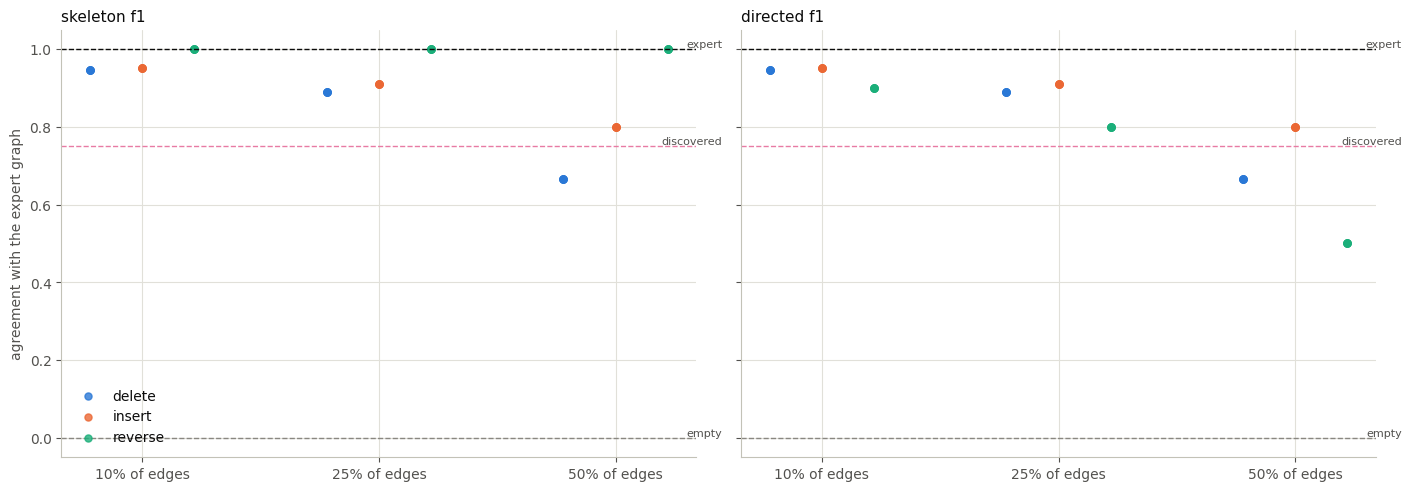

In [6]:
# figure 2: graph quality of the perturbed graphs per kind and strength
kind_colors = {'delete': ev.COLORS[0], 'insert': ev.COLORS[1], 'reverse': ev.COLORS[2]}
ref_style = {'expert': ('*', ev.INK['primary']), 'discovered': ('D', ev.COLORS[4]), 'empty': ('X', ev.INK['muted'])}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True, layout='constrained')
for ax, metric in zip(axes, ['skeleton_f1', 'directed_f1']):
    for k, kind in enumerate(KINDS):
        d = summary[summary.kind == kind]
        for fraction in FRACTIONS:
            v = d.loc[d.fraction == fraction, metric]
            x = FRACTIONS.index(fraction) + (k - 1) * 0.22
            ax.scatter(np.full(len(v), x), v, color=kind_colors[kind], s=26, alpha=0.8, label=kind if fraction == FRACTIONS[0] else None)
    for name, (marker, color) in ref_style.items():
        ax.axhline(summary.set_index('graph').loc[name, metric], color=color, linewidth=1, linestyle='--')
        ax.text(2.45, summary.set_index('graph').loc[name, metric], name, fontsize=8, va='bottom', ha='right', color=ev.INK['secondary'])
    ax.set_xticks(range(len(FRACTIONS)), [f'{f:.0%} of edges' for f in FRACTIONS])
    ax.set_title(metric.replace('_', ' '))
axes[0].set_ylabel('agreement with the expert graph')
axes[0].legend(loc='lower left')
ev.save_figure(fig, f'09_{SUBSYSTEM}_graph_quality')
plt.show()

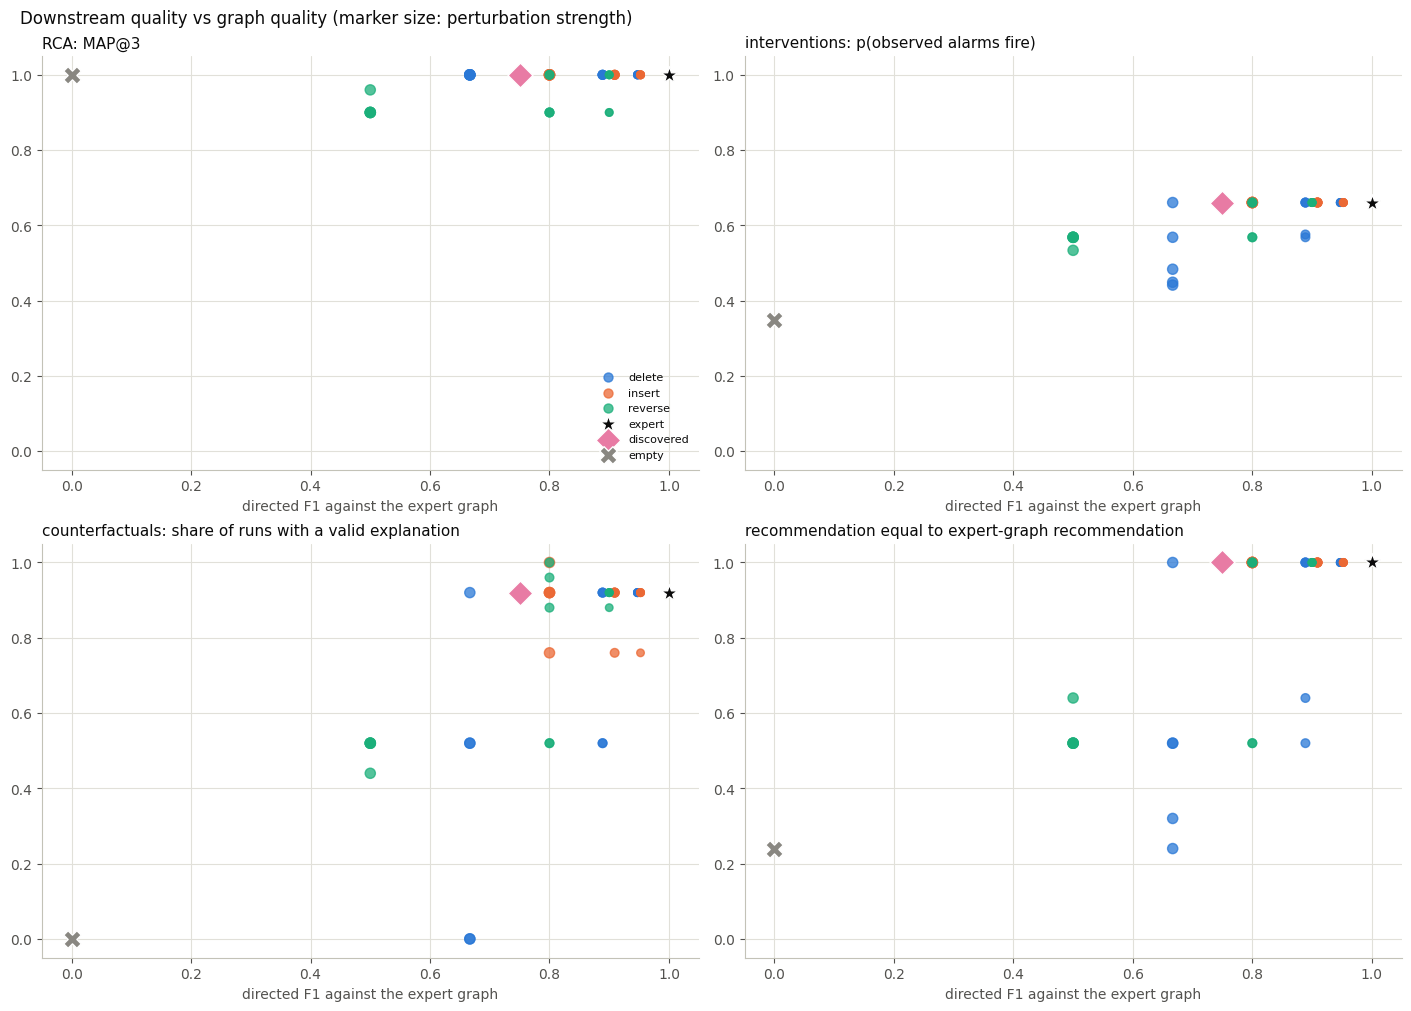

In [7]:
# figure 3: downstream quality against directed f1 for every graph
panels = [('map@3', 'RCA: MAP@3'), ('replay_p_fires_all', 'interventions: p(observed alarms fire)'),
          ('cf_valid_share', 'counterfactuals: share of runs with a valid explanation'),
          ('same_recommendation_as_expert', 'recommendation equal to expert-graph recommendation')]
fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout='constrained')
for ax, (metric, title) in zip(axes.flat, panels):
    for kind in KINDS:
        d = summary[summary.kind == kind]
        ax.scatter(d.directed_f1, d[metric], s=24 + 60 * d.fraction, color=kind_colors[kind], alpha=0.75, label=f'{kind}')
    for name, (marker, color) in ref_style.items():
        r = summary.set_index('graph').loc[name]
        ax.scatter(r.directed_f1, r[metric], marker=marker, s=160, color=color, edgecolor=ev.INK['surface'], zorder=4, label=name)
    ax.set_xlabel('directed F1 against the expert graph')
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(title)
axes[0, 0].legend(loc='lower right', fontsize=8)
fig.suptitle('Downstream quality vs graph quality (marker size: perturbation strength)', x=0.01, ha='left')
ev.save_figure(fig, f'09_{SUBSYSTEM}_downstream_vs_graph')
plt.show()

In [8]:
# spearman correlations between graph quality and downstream quality over the perturbed graphs
perturbed = summary[summary.kind.isin(KINDS)]
rng = np.random.default_rng(SEED)
downstream_cols = ['map@3', 'median_margin', 'replay_p_fires_all', 'replay_p_fires_supported', 'cf_valid_share',
                   'cf_validity_mean', 'cf_improvement_mean', 'cf_action_recall', 'same_recommendation_as_expert']
corr_rows = []
for graph_metric in ['directed_f1', 'skeleton_f1', 'shd']:
    for target in downstream_cols:
        x, y = perturbed[graph_metric].to_numpy(), perturbed[target].to_numpy()
        rho = stats.spearmanr(x, y).statistic if np.std(y) > 0 and np.std(x) > 0 else np.nan
        boot = []
        for _ in range(1000):
            idx = rng.integers(0, len(x), len(x))
            if np.std(x[idx]) > 0 and np.std(y[idx]) > 0:
                boot.append(stats.spearmanr(x[idx], y[idx]).statistic)
        low, high = (np.quantile(boot, [0.025, 0.975]) if boot else (np.nan, np.nan))
        corr_rows.append({'graph_metric': graph_metric, 'downstream': target, 'spearman': rho, 'ci_low': low, 'ci_high': high,
                          'downstream_varies': bool(np.std(y) > 0)})
correlations = pd.DataFrame(corr_rows)
ev.save_table(correlations, f'09_{SUBSYSTEM}_correlations')
correlations[correlations.graph_metric == 'directed_f1'].round(3)

,graph_metric,downstream,spearman,ci_low,ci_high,downstream_varies
0,directed_f1,map@3,0.425,0.167,0.641,True
1,directed_f1,median_margin,0.306,0.007,0.570,True
2,directed_f1,replay_p_fires_all,0.657,0.469,0.766,True
3,directed_f1,replay_p_fires_supported,0.657,0.465,0.775,True
4,directed_f1,cf_valid_share,0.504,0.216,0.715,True
5,directed_f1,cf_validity_mean,0.502,0.207,0.721,True
6,directed_f1,cf_improvement_mean,0.551,0.287,0.726,True
7,directed_f1,cf_action_recall,0.592,0.387,0.751,True
8,directed_f1,same_recommendation_as_expert,0.647,0.459,0.760,True


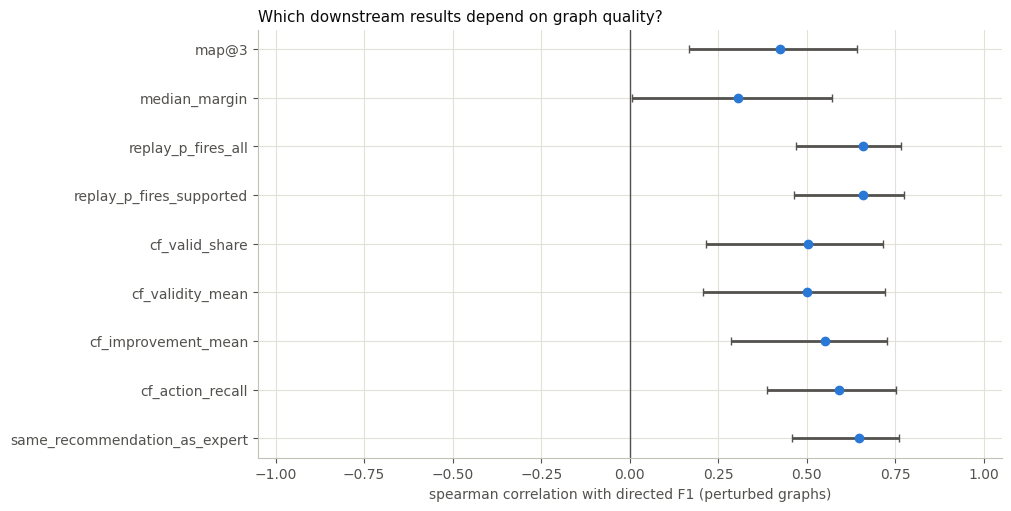

In [9]:
# figure 4: spearman correlation of downstream measures with directed f1 (95% bootstrap intervals)
c = correlations[correlations.graph_metric == 'directed_f1'].set_index('downstream').loc[downstream_cols]
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
y = np.arange(len(c))
ax.errorbar(c.spearman, y, xerr=[c.spearman - c.ci_low, c.ci_high - c.spearman], fmt='o', color=ev.COLORS[0],
            ecolor=ev.INK['secondary'], capsize=3)
for yi, (name, row) in zip(y, c.iterrows()):
    if not row.downstream_varies:
        ax.text(0.02, yi, 'constant over all graphs', va='center', fontsize=8, color=ev.INK['secondary'])
ax.axvline(0, color=ev.INK['secondary'], linewidth=1)
ax.set_yticks(y, c.index)
ax.invert_yaxis()
ax.set_xlim(-1.05, 1.05)
ax.set_xlabel('spearman correlation with directed F1 (perturbed graphs)')
ax.set_title('Which downstream results depend on graph quality?')
ev.save_figure(fig, f'09_{SUBSYSTEM}_correlations')
plt.show()

**Dependence between the 45 graphs.**
- The five graphs of one perturbation level are replicates of the same expert graph with identical directed F1, and all graphs are evaluated on the same 25 recordings from **four fault-scenario clusters**.
- The bootstrap above resamples graphs as if they were independent, so its intervals are too narrow.
- Below, the correlation is recomputed over the **nine perturbation-level means**. Its p-values are **exploratory** as well: the nine conditions are not independent industrial datasets.

In [10]:
# spearman over the nine perturbation-level means (5 replicates averaged per level); exploratory p-values
level_rows = []
reported = correlations[correlations.graph_metric == 'directed_f1'].set_index('downstream')
for target in downstream_cols:
    varies = by_level[target].std() > 0
    res = stats.spearmanr(by_level['directed_f1'], by_level[target]) if varies else None
    level_rows.append({'downstream': target, 'spearman_45_graphs': reported.loc[target, 'spearman'],
                       'spearman_9_levels': res.statistic if varies else np.nan,
                       'p_9_levels_exploratory': res.pvalue if varies else np.nan})
level_corr = pd.DataFrame(level_rows)
ev.save_table(level_corr, f'09_{SUBSYSTEM}_correlations_by_level')
print('distinct directed f1 values among the 45 perturbed graphs:', perturbed.directed_f1.round(6).nunique(),
      '| fault-scenario clusters:', per_run.fold.nunique())
level_corr.round(3)

distinct directed f1 values among the 45 perturbed graphs: 8 | fault-scenario clusters: 4


,downstream,spearman_45_graphs,spearman_9_levels,p_9_levels_exploratory
0,map@3,0.425,0.455,0.218
1,median_margin,0.306,0.536,0.137
2,replay_p_fires_all,0.657,0.767,0.016
3,replay_p_fires_supported,0.657,0.767,0.016
4,cf_valid_share,0.504,0.653,0.057
5,cf_validity_mean,0.502,0.653,0.057
6,cf_improvement_mean,0.551,0.636,0.066
7,cf_action_recall,0.592,0.785,0.012
8,same_recommendation_as_expert,0.647,0.767,0.016


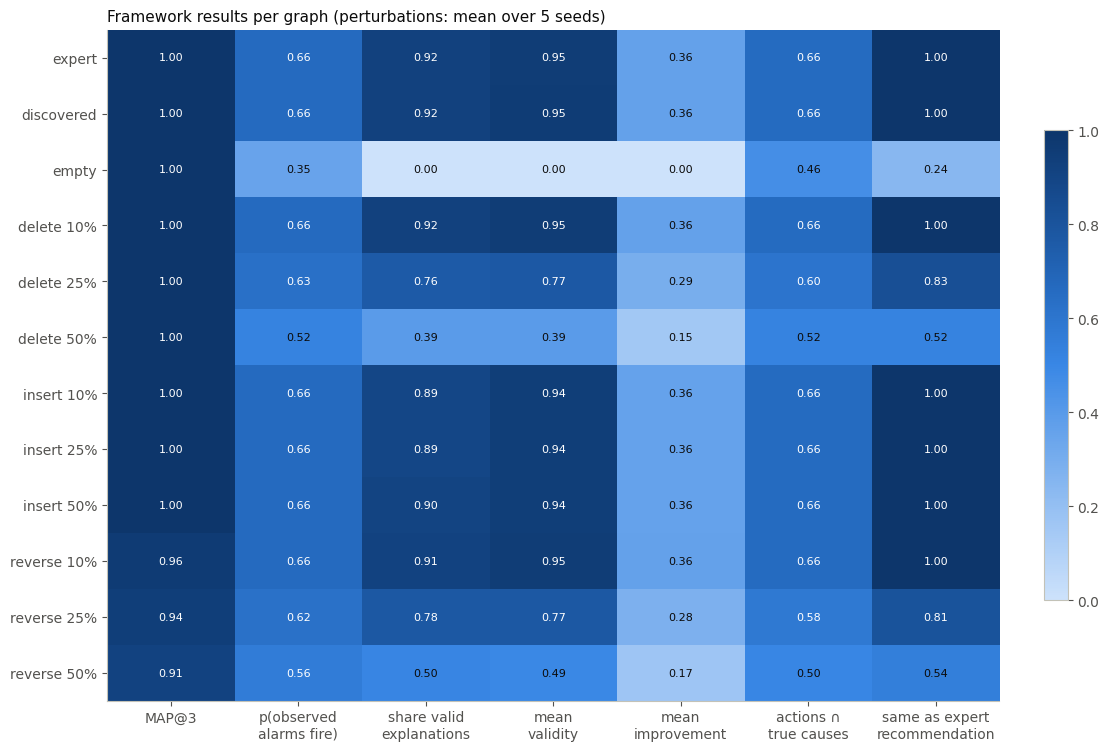

In [11]:
# figure 5: downstream measures per perturbation kind and strength (mean over seeds)
heat = by_level[['map@3', 'replay_p_fires_all', 'cf_valid_share', 'cf_validity_mean', 'cf_improvement_mean',
                 'cf_action_recall', 'same_recommendation_as_expert']]
heat = pd.concat([reference[heat.columns], heat.set_axis([f'{k} {f:.0%}' for k, f in heat.index])])
fig, ax = plt.subplots(figsize=(11, 0.45 * len(heat) + 2), layout='constrained')
image = ax.imshow(heat.to_numpy(dtype=float), cmap=ev.sequential_cmap(), vmin=0, vmax=1, aspect='auto')
for (i, j), v in np.ndenumerate(heat.to_numpy(dtype=float)):
    ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color=ev.INK['surface'] if v > 0.55 else ev.INK['primary'])
ax.set_xticks(range(heat.shape[1]), ['MAP@3', 'p(observed\nalarms fire)', 'share valid\nexplanations', 'mean\nvalidity',
                                     'mean\nimprovement', 'actions ∩\ntrue causes', 'same as expert\nrecommendation'])
ax.set_yticks(range(len(heat)), heat.index)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.7)
ax.set_title('Framework results per graph (perturbations: mean over 5 seeds)')
ev.save_figure(fig, f'09_{SUBSYSTEM}_results_heatmap')
plt.show()

## 3. Paired comparisons with the expert graph

Per held-out run, each graph is compared with the expert graph (Wilcoxon signed-rank test on the paired per-run values). Runs with identical values carry no information about the direction and are dropped, as usual for this test.

**These p-values are exploratory.** The 25 recordings come from four fault scenarios, and recordings within one scenario respond almost identically to a graph change, so they are not independent. The scenario-level table after the tests is the more honest summary.

In [12]:
# paired tests per graph family (perturbed graphs pooled per kind and strength)
def paired(metric, name_filter):
    base = per_run[per_run.graph == 'expert'].set_index('recording_id')[metric]
    rows = []
    for (kind, fraction), group in per_run[name_filter(per_run)].groupby(['kind', 'fraction'], dropna=False):
        other = group.groupby('recording_id')[metric].mean()
        diff = (other - base.reindex(other.index)).dropna()
        nonzero = diff[diff != 0]
        p = stats.wilcoxon(nonzero).pvalue if len(nonzero) >= 6 else np.nan
        rows.append({'metric': metric, 'kind': kind, 'fraction': fraction, 'mean_difference': diff.mean(),
                     'runs_differing': len(nonzero), 'wilcoxon_p': p})
    return rows
tests = []
for metric in ['ap@3', 'validity_probability', 'improvement', 'replay_p_fires']:
    tests += paired(metric, lambda d: d.graph != 'expert')
paired_tests = pd.DataFrame(tests)
ev.save_table(paired_tests, f'09_{SUBSYSTEM}_paired_tests')
paired_tests.round(4)

,metric,kind,fraction,mean_difference,runs_differing,wilcoxon_p
0,ap@3,delete,0.10,0.0000,0,NaN
1,ap@3,delete,0.25,0.0000,0,NaN
2,ap@3,delete,0.50,0.0000,0,NaN
3,ap@3,discovered,NaN,0.0000,0,NaN
4,ap@3,empty,1.00,0.0000,0,NaN
5,ap@3,insert,0.10,0.0000,0,NaN
6,ap@3,insert,0.25,0.0000,0,NaN
7,ap@3,insert,0.50,0.0000,0,NaN
8,ap@3,reverse,0.10,-0.0400,6,0.0312
9,ap@3,reverse,0.25,-0.0600,6,0.0312


**Scenario-level view.** Per-recording differences to the expert graph are averaged within each of the four fault scenarios. The counts give how many scenarios improve, deteriorate or tie; a tie means equal up to floating-point rounding (|difference| < 1e-9), and the largest absolute difference shows how small the non-ties are. With four scenarios even a uniform sign gives a two-sided sign-test p of 0.125, so the counts describe consistency, not significance.

In [13]:
# per-scenario mean difference to the expert graph, per perturbation level (and the discovered and empty graphs)
base = per_run[per_run.graph == 'expert'].set_index('recording_id')
scenarios = sorted(per_run.fold.unique())
TIE = 1e-9  # differences below this are floating-point rounding from averaging the replicates
scen_rows = []
for (kind, fraction), group in per_run[per_run.graph != 'expert'].groupby(['kind', 'fraction'], dropna=False):
    per_rec = group.groupby(['recording_id', 'fold'])[['ap@3', 'validity_probability', 'improvement', 'replay_p_fires']].mean().reset_index()
    for metric in ['ap@3', 'validity_probability', 'improvement', 'replay_p_fires']:
        diff = per_rec[metric].to_numpy() - base[metric].reindex(per_rec.recording_id).to_numpy()
        by_s = pd.Series(diff).groupby(per_rec.fold.to_numpy()).mean()
        scen_rows.append({'metric': metric, 'kind': kind, 'fraction': fraction, 'pooled': diff.mean(),
                          **{f: by_s[f] for f in scenarios},
                          'scenarios_better': int((by_s > TIE).sum()), 'scenarios_worse': int((by_s < -TIE).sum()),
                          'scenarios_tied': int((by_s.abs() <= TIE).sum()), 'max_abs_difference': float(by_s.abs().max())})
scenario_diff = pd.DataFrame(scen_rows)
ev.save_table(scenario_diff, f'09_{SUBSYSTEM}_scenario_differences')
scenario_diff[scenario_diff.metric.isin(['validity_probability', 'ap@3'])].round(3)

,metric,kind,fraction,pooled,exp_22,exp_27,exp_28,exp_35,scenarios_better,scenarios_worse,scenarios_tied,max_abs_difference
0,ap@3,delete,0.10,0.000,0.000,0.000,0.000,0.000,0,0,4,0.000
1,validity_probability,delete,0.10,0.000,0.000,0.000,0.000,0.000,0,0,4,0.000
4,ap@3,delete,0.25,0.000,0.000,0.000,0.000,0.000,0,0,4,0.000
5,validity_probability,delete,0.25,-0.179,0.000,0.000,-0.383,-0.361,0,2,2,0.383
8,ap@3,delete,0.50,0.000,0.000,0.000,0.000,0.000,0,0,4,0.000
9,validity_probability,delete,0.50,-0.558,-0.375,-0.397,-0.767,-0.721,0,4,0,0.767
12,ap@3,discovered,NaN,0.000,0.000,0.000,0.000,0.000,0,0,4,0.000
13,validity_probability,discovered,NaN,0.004,0.007,0.003,-0.007,0.015,3,1,0,0.015
16,ap@3,empty,1.00,0.000,0.000,0.000,0.000,0.000,0,0,4,0.000
17,validity_probability,empty,1.00,-0.950,-0.938,-0.993,-0.958,-0.902,0,4,0,0.993


In [14]:
# equal directed f1, different usefulness: which scenarios carry the difference?
contrasts = [(('insert', 0.5), ('reverse', 0.25)), (('insert', 0.5), ('delete', 0.25))]
per_level_scen = (per_run[per_run.kind.isin(KINDS)].groupby(['kind', 'fraction', 'fold']).validity_probability.mean())
contrast_rows = []
for a, b in contrasts:
    row = {'graph_a': f'{a[0]} {a[1]:.0%}', 'f1_a': by_level.loc[a, 'directed_f1'], 'graph_b': f'{b[0]} {b[1]:.0%}',
           'f1_b': by_level.loc[b, 'directed_f1'], 'validity_a': by_level.loc[a, 'cf_validity_mean'],
           'validity_b': by_level.loc[b, 'cf_validity_mean']}
    row.update({f'diff_{f}': per_level_scen.loc[(*a, f)] - per_level_scen.loc[(*b, f)] for f in scenarios})
    contrast_rows.append(row)
equal_f1 = pd.DataFrame(contrast_rows)
ev.save_table(equal_f1, f'09_{SUBSYSTEM}_f1_contrasts')
equal_f1.round(3)

,graph_a,f1_a,graph_b,f1_b,validity_a,validity_b,diff_exp_22,diff_exp_27,diff_exp_28,diff_exp_35
0,insert 50%,0.8,reverse 25%,0.800,0.944,0.775,-0.003,-0.002,0.383,0.326
1,insert 50%,0.8,delete 25%,0.889,0.944,0.771,0.000,0.000,0.380,0.339


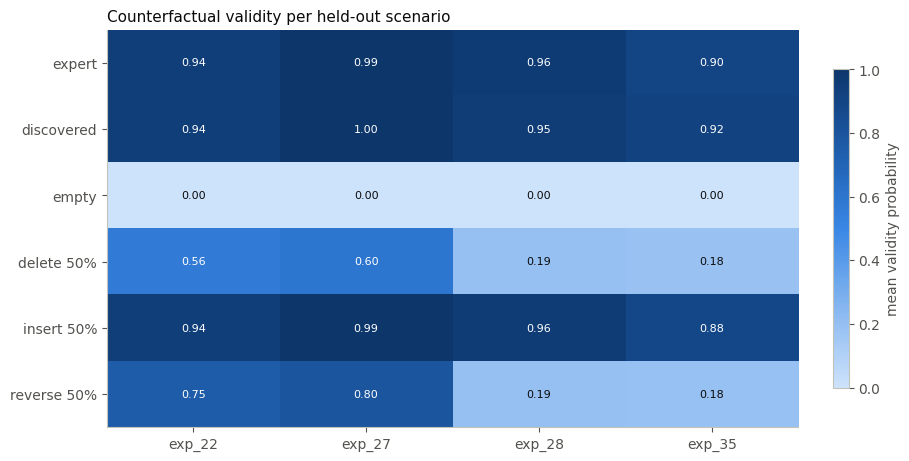

In [15]:
# figure 6: where do perturbed graphs break the explanations? validity per scenario and kind (50% perturbations)
d = per_run[(per_run.fraction == 0.5) | per_run.graph.isin(['expert', 'discovered', 'empty'])].copy()
d['group'] = np.where(d.kind.isin(KINDS), d.kind + ' 50%', d.graph)
pivot = d.groupby(['group', 'fold']).validity_probability.mean().unstack('fold')
pivot = pivot.reindex(['expert', 'discovered', 'empty'] + [f'{k} 50%' for k in KINDS])
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
image = ax.imshow(pivot.to_numpy(dtype=float), cmap=ev.sequential_cmap(), vmin=0, vmax=1, aspect='auto')
for (i, j), v in np.ndenumerate(pivot.to_numpy(dtype=float)):
    ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color=ev.INK['surface'] if v > 0.55 else ev.INK['primary'])
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(len(pivot)), pivot.index)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label='mean validity probability')
ax.set_title('Counterfactual validity per held-out scenario')
ev.save_figure(fig, f'09_{SUBSYSTEM}_validity_by_scenario')
plt.show()

## 4. Final summary table

In [16]:
# thesis summary table: reference graphs and the 50% perturbations
final_cols = ['n_pred_edges', 'skeleton_f1', 'directed_f1', 'shd', 'map@3', 'top1', 'replay_p_fires_all',
              'replay_p_fires_supported', 'cf_valid_share', 'cf_validity_mean', 'cf_improvement_mean', 'cf_action_recall',
              'same_recommendation_as_expert']
final = pd.concat([summary.set_index('graph').loc[['expert', 'discovered', 'empty'], final_cols],
                   summary[summary.kind.isin(KINDS)].groupby(['kind', 'fraction'])[final_cols].mean()
                   .set_axis([f'{k} {f:.0%} (mean of 5)' for k, f in by_level.index])])
ev.save_table(final.reset_index(names='graph'), f'09_{SUBSYSTEM}_final_table')
final.round(3)

,n_pred_edges,skeleton_f1,directed_f1,shd,map@3,top1,replay_p_fires_all,replay_p_fires_supported,cf_valid_share,cf_validity_mean,cf_improvement_mean,cf_action_recall,same_recommendation_as_expert
expert,10.0,1.000,1.000,0.0,1.000,1.0,0.661,1.000,0.920,0.950,0.360,0.660,1.000
discovered,6.0,0.750,0.750,4.0,1.000,1.0,0.661,1.000,0.920,0.954,0.360,0.660,1.000
empty,0.0,0.000,0.000,10.0,1.000,1.0,0.348,0.527,0.000,0.000,0.000,0.460,0.240
delete 10% (mean of 5),9.0,0.947,0.947,1.0,1.000,1.0,0.661,1.000,0.920,0.950,0.360,0.660,1.000
delete 25% (mean of 5),8.0,0.889,0.889,2.0,1.000,1.0,0.625,0.946,0.760,0.771,0.294,0.604,0.832
delete 50% (mean of 5),5.0,0.667,0.667,5.0,1.000,1.0,0.521,0.788,0.392,0.391,0.150,0.517,0.520
insert 10% (mean of 5),11.0,0.952,0.952,1.0,1.000,1.0,0.661,1.000,0.888,0.944,0.359,0.660,1.000
insert 25% (mean of 5),12.0,0.909,0.909,2.0,1.000,1.0,0.661,1.000,0.888,0.944,0.359,0.660,1.000
insert 50% (mean of 5),15.0,0.800,0.800,5.0,1.000,1.0,0.661,1.000,0.904,0.944,0.359,0.660,1.000
reverse 10% (mean of 5),10.0,1.000,0.900,1.0,0.960,1.0,0.661,1.000,0.912,0.949,0.360,0.660,1.000


## 5. Findings

**1. Graph quality matters, but not for every task in the same way.**
- **Evidence base.** 45 perturbed graphs, but only nine distinct perturbation levels (the five replicates of a level share their directed F1), evaluated on 25 recordings from **four fault-scenario clusters**. All p-values and intervals below are exploratory.
- Every downstream measure correlates positively with directed F1 over the 45 perturbed graphs (Spearman, 95% bootstrap intervals over graphs, which treat dependent graphs as independent and are therefore too narrow):
  - replay of real manipulations: 0.66 [0.47, 0.77]
  - recommendation equal to the expert-graph recommendation: 0.65 [0.46, 0.76]
  - counterfactual action recall: 0.59
  - target improvement: 0.55
  - share of valid explanations: 0.50 [0.22, 0.72]
  - MAP@3: 0.43 [0.17, 0.64]
  - RCA separation margin: 0.31 [0.01, 0.57]
- **Over the nine level means** the correlations keep their sign and are larger (exploratory p):
  - replay: 0.77 (p 0.016)
  - recommendation stability: 0.77 (p 0.016)
  - action recall: 0.79 (p 0.012)
  - share of valid explanations: 0.65 (p 0.057)
  - target improvement: 0.64 (p 0.066)
  - MAP@3: 0.46 (p 0.22)
- **RCA is the least sensitive task.** MAP@3 stays at 1.00 for every deleted or inserted edge, and even for the empty graph. It drops only when edges are *reversed* (0.96 / 0.94 / 0.91 at 10 / 25 / 50%). A reversed cause → alarm edge makes the root cause a child of its own alarm, so its change is partly explained away.
- **Actionable explanations are the most sensitive task.** At 50% perturbation:
  - Deletion lowers the share of valid explanations from 0.92 to 0.39 and recommendation stability to 0.52.
  - Reversal lowers them to 0.50 and 0.54.
  - The empty graph produces no valid explanation at all.

**2. The kind of error matters more than the amount.**
- Inserting false edges is almost harmless. At 50% insertion (directed F1 0.80), validity stays at 0.94 and the recommendation equals the expert one in every run. The fitted mechanisms learn that a spurious parent carries no information.
- **Missing and reversed edges** remove the cause → alarm paths that every intervention and counterfactual relies on.
- **Their greater impact appears at perturbation strengths of 25% or more**, not uniformly (scenario-level table):
  - **At 10%** no kind changes validity materially: all scenario differences are 0.025 or smaller.
  - **At 25%** deletion and reversal lower validity in two of the four scenarios (exp_28 −0.38 and −0.39, exp_35 −0.36 and −0.35); exp_22 and exp_27 are essentially unaffected (|difference| ≤ 0.003).
  - **At 50%** they lower it in all four scenarios (deletion −0.38 to −0.77, reversal −0.19 to −0.77), while 50% insertion changes it by 0.022 at most.
- So a graph with *lower* F1 can be *more* useful: insert 50% (F1 0.80) gives 0.90 valid explanations, delete 25% (F1 0.89) only 0.76.
- At *equal* F1 the usefulness differs too: insert 50% and reverse 25% both have directed F1 0.80, but mean validity is 0.944 vs 0.775. The difference comes entirely from exp_28 (+0.38) and exp_35 (+0.33); in exp_22 and exp_27 the two graphs are essentially equally useful (differences ≤ 0.003; equal-F1 contrast table). The relationship is monotone in tendency, but **F1 alone does not predict usefulness**. It matters *which* edges are wrong, and the scatter plots show large spread at equal F1 depending on whether a cause → alarm edge was hit.

**3. The discovered graph is as useful as the expert graph here.**
- Directed F1 is 0.75 (6 edges in the acyclic SCM graph), yet the discovered graph gives the same RCA, the same replay agreement and the same recommendations as the expert graph in all 25 runs.
- Its errors (two missed edges, two unoriented edges, two alarm–alarm extras) do not touch the cause → alarm edges of the supported alarms.
- This is a statement about *this* subsystem and these error locations, not a general equivalence.

**4. Paired comparisons** (per run, against the expert graph; exploratory):
- 50% deletion and 50% reversal reduce validity, improvement and replay agreement in all 25 runs and in all four scenarios. The recording-level Wilcoxon p < 0.001 is exploratory: recordings within a scenario are dependent, so the effective sample is four scenarios, for which even a uniform sign gives p = 0.125.
- Insertions change validity only marginally (mean −0.006, at most 0.025 in any scenario). The small Wilcoxon p comes from many runs differing by tiny amounts and is not evidence of a relevant effect.
- The discovered graph's per-run differences from the expert graph are small in both directions.

**Notes.**
- This notebook uses 100 abducted worlds per counterfactual (notebook 08: 200). Explanations close to the 0.9 validity threshold can flip with the sample, so the expert graph reaches 0.92 here instead of 1.00. Compare graphs within one notebook, not across notebooks.
- *Thesis note:* the answer to the research question for coolant is that graph quality matters little for **locating** the root cause and a lot for **acting** on it. Errors that delete or reverse the edges from causes to the observed symptoms are the ones that destroy actionability. Notebook 10 tests whether RCA itself becomes graph-dependent when root causes are not constant in normal operation.